# Proyecto Final de Minería de Datos — Modelos propios

Este notebook corresponde a mi entrega individual (`modelos_3.ipynb`).

Contiene:
1. Un resumen del EDA para conservar la secuencia del proyecto.
2. Regresión lineal para estimar `ProductRelated_Duration`.
3. Reglas de asociación con Apriori para encontrar patrones de compra.

El dataset se descarga desde el repositorio, por lo que el notebook funciona de forma independiente.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

URL_RAW = 'https://raw.githubusercontent.com/Bashte54/Proyecto_MineriaDatos/main/online_shoppers_intention.csv'
df_crudo = pd.read_csv(URL_RAW)

print('Dataset crudo:', df_crudo.shape)
display(df_crudo.head(3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Dataset crudo: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.0,0.0,0.1,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*utcnow.*")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Parte 1 — Resumen del análisis exploratorio

Antes de modelar se revisó el dataset original: tipos de datos, valores faltantes, duplicados, consistencia y distribución de `Revenue`. También se construyeron histogramas, boxplots, gráficos de barras, diagramas de dispersión y el mapa de calor de correlaciones.

In [15]:
resumen_eda = pd.DataFrame({
    'Valor': [
        df_crudo.shape[0],
        df_crudo.shape[1],
        int(df_crudo.isna().sum().sum()),
        int(df_crudo.duplicated().sum()),
        int(df_crudo['Revenue'].sum()),
        round(df_crudo['Revenue'].mean() * 100, 2)
    ]
}, index=[
    'Filas', 'Columnas', 'Valores faltantes', 'Filas duplicadas',
    'Sesiones con compra', 'Tasa de compra (%)'
])
display(resumen_eda)

corr = df_crudo[['BounceRates', 'ExitRates', 'ProductRelated', 'ProductRelated_Duration']].corr()
display(corr.round(2))

,Valor
Filas,12330.00
Columnas,18.00
Valores faltantes,0.00
Filas duplicadas,125.00
Sesiones con compra,1908.00
Tasa de compra (%),15.47


,BounceRates,ExitRates,ProductRelated,ProductRelated_Duration
BounceRates,1.00,0.91,-0.20,-0.18
ExitRates,0.91,1.00,-0.29,-0.25
ProductRelated,-0.20,-0.29,1.00,0.86
ProductRelated_Duration,-0.18,-0.25,0.86,1.00


**Observaciones:**

- El dataset original tiene **12,330 sesiones y 18 variables**, sin valores faltantes.
- Hay **125 filas duplicadas completas**; al retirarlas quedan **12,205 sesiones**.
- La tasa de compra ronda el **15 %**, por lo que las clases están desbalanceadas.
- `BounceRates` y `ExitRates` tienen correlación **0.91**; `ProductRelated` y `ProductRelated_Duration`, **0.86**.
- `PageValues` se conserva para el análisis, pero se excluye de los modelos por posible fuga de información.

## Preparación de los datos para los modelos

Se parte del dataset crudo, se eliminan los duplicados y se construyen las mismas cinco variables derivadas que usa el equipo. Así los resultados son comparables con los de sus notebooks.

In [16]:
datos = df_crudo.drop_duplicates(keep='first').reset_index(drop=True).copy()

datos['PaginasTotales'] = datos['Administrative'] + datos['Informational'] + datos['ProductRelated']
datos['VisitoInformativas'] = (datos['Informational'] > 0).astype(int)
datos['TiempoPromedioProducto'] = (
    datos['ProductRelated_Duration'] / datos['ProductRelated'].replace(0, np.nan)
).fillna(0)
datos['PorcentajePaginasProducto'] = (
    datos['ProductRelated'] / datos['PaginasTotales'].replace(0, np.nan)
).fillna(0)
datos['TiempoPromedioPagina'] = (
    (datos['Administrative_Duration'] + datos['Informational_Duration'] + datos['ProductRelated_Duration'])
    / datos['PaginasTotales'].replace(0, np.nan)
).fillna(0)

print('Dataset para modelos:', datos.shape)
print('Sesiones con compra:', round(datos['Revenue'].mean() * 100, 2), '%')
display(datos.head(3))

Dataset para modelos: (12205, 23)
Sesiones con compra: 15.63 %


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,PaginasTotales,VisitoInformativas,TiempoPromedioProducto,PorcentajePaginasProducto,TiempoPromedioPagina
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False,1,0,0.0,1.0,0.0
1,0,0.0,0,0.0,2,64.0,0.0,0.1,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False,2,0,32.0,1.0,32.0
2,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False,1,0,0.0,1.0,0.0


---
## PARTE 2 — Regresión lineal

**Objetivo:** estimar `ProductRelated_Duration` en segundos.

Se excluyen la propia variable objetivo, `Revenue` y `PageValues` (posible fuga de información), y las variables derivadas calculadas a partir de la duración.

In [17]:
excluidas = [
    'Revenue', 'ProductRelated_Duration', 'PageValues',
    'PaginasTotales', 'VisitoInformativas', 'TiempoPromedioProducto',
    'PorcentajePaginasProducto', 'TiempoPromedioPagina'
]
excluidas = [c for c in excluidas if c in datos.columns]

X_regresion = datos.drop(columns=excluidas).copy()
y_objetivo = datos['ProductRelated_Duration'].copy()

X_ent, X_pru, y_ent, y_pru = train_test_split(
    X_regresion, y_objetivo, test_size=0.20, random_state=42
)

cat_onehot = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType']
X_e, X_p = X_ent.copy(), X_pru.copy()

for col in cat_onehot:
    niveles = sorted(X_e[col].astype(str).unique())
    X_e[col] = pd.Categorical(X_e[col].astype(str), categories=niveles)
    X_p[col] = pd.Categorical(X_p[col].astype(str), categories=niveles)

X_e['Weekend'] = X_e['Weekend'].astype(int)
X_p['Weekend'] = X_p['Weekend'].astype(int)

X_e_cod = pd.get_dummies(X_e, columns=cat_onehot, dtype=int, drop_first=True)
X_p_cod = pd.get_dummies(X_p, columns=cat_onehot, dtype=int, drop_first=True)
X_p_cod = X_p_cod.reindex(columns=X_e_cod.columns, fill_value=0)

print('Entrenamiento:', X_e_cod.shape, '| Prueba:', X_p_cod.shape)
print('Mismas columnas:', X_e_cod.columns.equals(X_p_cod.columns))
print('Valores faltantes:', int(X_e_cod.isna().sum().sum()), int(X_p_cod.isna().sum().sum()))

Entrenamiento: (9764, 64) | Prueba: (2441, 64)
Mismas columnas: True
Valores faltantes: 0 0


**Observaciones:**

- Se usaron **9,764 sesiones para entrenamiento** y **2,441 para prueba** (80/20, `random_state=42`).
- Después de la codificación quedaron **64 características** en ambos conjuntos.
- No hay valores faltantes y las columnas están alineadas.
- Se excluyeron `PageValues`, `Revenue` y las variables derivadas de la duración para evitar fuga de información.

In [18]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_e_cod, y_ent)

pred_ent = modelo_lineal.predict(X_e_cod)
pred_pru = modelo_lineal.predict(X_p_cod)

def resumen_metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {
        'MAE': mean_absolute_error(y_real, y_pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2': r2_score(y_real, y_pred)
    }

metricas = pd.DataFrame({
    'Entrenamiento': resumen_metricas(y_ent, pred_ent),
    'Prueba': resumen_metricas(y_pru, pred_pru)
}).round(4)
display(metricas)

pred_media = np.full(shape=len(y_pru), fill_value=y_ent.mean())
print('Referencia (predecir la media) -> MAE:', round(mean_absolute_error(y_pru, pred_media), 2),
      '| R2:', round(r2_score(y_pru, pred_media), 4))
print('R2 en prueba:', round(r2_score(y_pru, pred_pru), 4))

,Entrenamiento,Prueba
MAE,481.2993,5.044308e+02
MSE,716075.9591,1.420718e+06
RMSE,846.2127,1.191939e+03
R2,0.7930,6.900000e-01


Referencia (predecir la media) -> MAE: 1129.55 | R2: -0.0001
R2 en prueba: 0.69


**Observaciones:**

- En **prueba**: MAE = **504.43 s**, MSE = 1,420,718.24, RMSE = **1,191.94 s** y R² = **0.6900**.
- En entrenamiento R² = 0.7930: el modelo generaliza peor a sesiones nuevas.
- Predecir siempre la media da MAE = 1,129.55 s y R² ≈ 0, así que el modelo lineal sí aporta información.
- La variable objetivo es muy asimétrica (máximo cerca de 43,171 s), lo que explica el RMSE elevado.

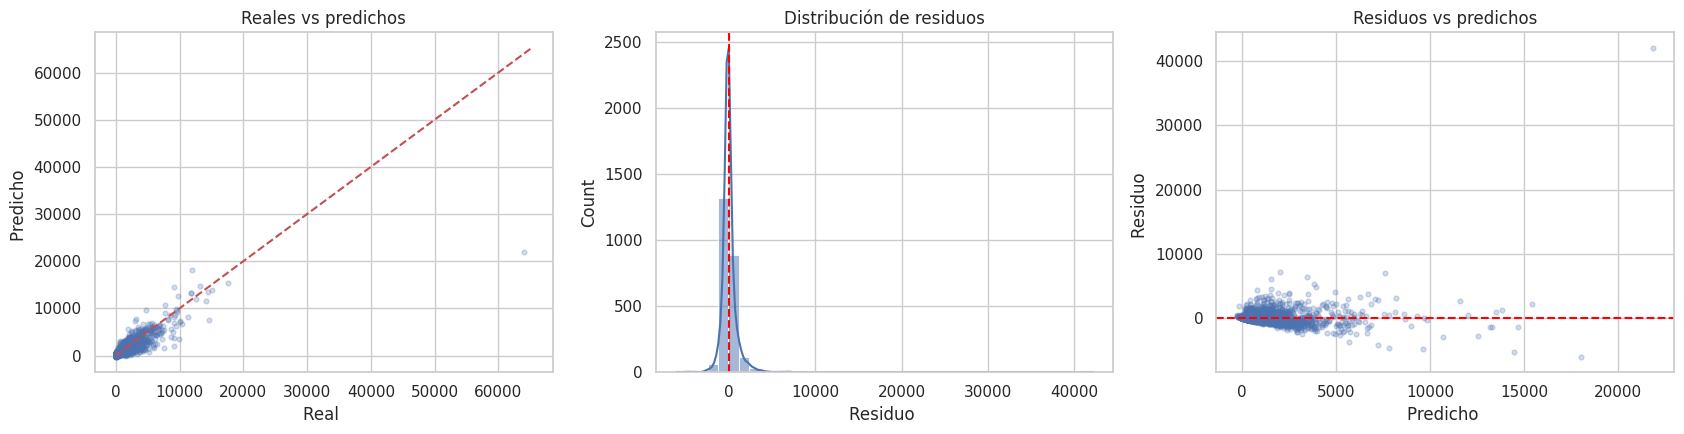

In [19]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

ejes[0].scatter(y_pru, pred_pru, alpha=0.25, s=12)
lim = [0, max(y_pru.max(), pred_pru.max()) * 1.02]
ejes[0].plot(lim, lim, 'r--')
ejes[0].set(xlabel='Real ', ylabel='Predicho ', title='Reales vs predichos')

residuos = y_pru - pred_pru
sns.histplot(residuos, bins=40, kde=True, ax=ejes[1])
ejes[1].axvline(0, color='red', ls='--')
ejes[1].set(title='Distribución de residuos', xlabel='Residuo ')

ejes[2].scatter(pred_pru, residuos, alpha=0.25, s=12)
ejes[2].axhline(0, color='red', ls='--')
ejes[2].set(title='Residuos vs predichos', xlabel='Predicho ', ylabel='Residuo ')

plt.tight_layout()
plt.show()

**Observaciones:**

- En reales vs predichos los puntos se alejan de la línea roja cuando aumenta la duración: el modelo subestima las sesiones largas.
- Los residuos se concentran cerca de cero, pero tienen una cola derecha amplia.
- La nube de residuos vs predichos no es uniforme, por lo que la linealidad pura tiene limitaciones.

In [20]:
coeficientes = (
    pd.DataFrame({'Variable': X_e_cod.columns, 'Coeficiente': modelo_lineal.coef_})
    .sort_values('Coeficiente')
)
display(pd.concat([coeficientes.head(8), coeficientes.tail(8)]))
print('Intercepto:', round(modelo_lineal.intercept_, 2))

,Variable,Coeficiente
5,BounceRates,-1537.245043
50,TrafficType_16,-261.325985
7,SpecialDay,-149.190213
54,TrafficType_20,-144.834438
46,TrafficType_11,-111.184315
25,Browser_10,-109.229385
55,TrafficType_3,-108.975135
31,Browser_4,-106.951659
13,Month_Mar,226.197866
52,TrafficType_19,230.369401


Intercepto: -262.19


**Observaciones:**

- `ExitRates` tiene el coeficiente positivo más alto (**+1,477.45 s** por unidad) y `BounceRates` el más negativo (**-1,537.25 s**), aunque ambas tasas están correlacionadas.
- `TrafficType_14` aporta alrededor de **+974.33 s** respecto a la categoría de referencia; `SpecialDay` cerca de **-149.19 s**.
- El intercepto es **-262.19 s**, sin interpretación física directa porque la duración no puede ser negativa.
- Los coeficientes son asociaciones del modelo, **no relaciones causales**.

---
## PARTE 3 — Reglas de asociación con Apriori

**Objetivo:** descubrir patrones de navegación asociados a la compra (`Compra`).

Se construye una tabla de 8 indicadores booleanos por sesión y se evalúan las reglas con **soporte, confianza y lift**.

In [21]:
try:
    from mlxtend.frequent_patterns import apriori, association_rules
except ImportError:
    !pip install -q mlxtend
    from mlxtend.frequent_patterns import apriori, association_rules

print('mlxtend listo')

mlxtend listo


In [22]:
med_pag = datos['ProductRelated'].median()
med_tiem = datos['ProductRelated_Duration'].median()
med_sal = datos['ExitRates'].median()

tabla_apriori = pd.DataFrame({
    'VisitoInformacion': datos['Informational'] > 0,
    'MuchasPaginasProducto': datos['ProductRelated'] > med_pag,
    'MuchoTiempoEnProductos': datos['ProductRelated_Duration'] > med_tiem,
    'SalidaAlta': datos['ExitRates'] > med_sal,
    'FinDeSemana': datos['Weekend'].astype(bool),
    'VisitanteNuevo': datos['VisitorType'].eq('New_Visitor'),
    'MesNoviembre': datos['Month'].eq('Nov'),
    'Compra': datos['Revenue'].astype(bool),
}, index=datos.index)

print('Formato de transacciones:', tabla_apriori.shape)
display((tabla_apriori.mean() * 100).round(2).sort_values(ascending=False))

Formato de transacciones: (12205, 8)


,0
MuchoTiempoEnProductos,50.00
SalidaAlta,49.65
MuchasPaginasProducto,49.49
MesNoviembre,24.43
FinDeSemana,23.42
VisitoInformacion,21.56
Compra,15.63
VisitanteNuevo,13.87


**Observaciones:**

- Se generaron **12,205 transacciones con 8 indicadores booleanos**.
- Los más frecuentes son `MuchoTiempoEnProductos` (50.00 %), `SalidaAlta` (49.65 %) y `MuchasPaginasProducto` (49.49 %).
- `Compra` aparece en el **15.63 %** de las sesiones, igual que la tasa global de conversión.
- Solo se conserva `Compra` como indicador del resultado para que las reglas tengan ese consecuente.

In [23]:
for soporte in [0.03, 0.05, 0.08]:
    itemsets_prueba = apriori(tabla_apriori, min_support=soporte, use_colnames=True)
    print(f'min_support={soporte}: {len(itemsets_prueba)} itemsets')

min_support=0.03: 64 itemsets
min_support=0.05: 38 itemsets
min_support=0.08: 26 itemsets


In [24]:
frecuentes = apriori(tabla_apriori, min_support=0.05, use_colnames=True)

reglas = association_rules(frecuentes, metric='confidence', min_threshold=0.20)
reglas = reglas[reglas['consequents'].apply(lambda c: set(c) == {'Compra'})]
reglas = reglas[~reglas['antecedents'].apply(lambda a: 'Compra' in a)]
reglas = reglas.sort_values('lift', ascending=False).reset_index(drop=True)

tabla_reglas = reglas[['antecedents', 'support', 'confidence', 'lift']].head(10).copy()
tabla_reglas['Antecedente'] = tabla_reglas['antecedents'].apply(lambda s: ' + '.join(sorted(s)))
tabla_reglas = tabla_reglas[['Antecedente', 'support', 'confidence', 'lift']]
display(tabla_reglas.round(4))
print('Reglas encontradas:', len(reglas))

,Antecedente,support,confidence,lift
0,MesNoviembre + MuchoTiempoEnProductos,0.0506,0.3373,2.1579
1,MesNoviembre,0.0623,0.2549,1.6303
2,VisitoInformacion,0.0502,0.2330,1.4904
3,MuchasPaginasProducto + MuchoTiempoEnProductos,0.0972,0.2304,1.4737
4,MuchoTiempoEnProductos,0.1115,0.2230,1.4267
5,MuchasPaginasProducto,0.1073,0.2169,1.3874


Reglas encontradas: 6


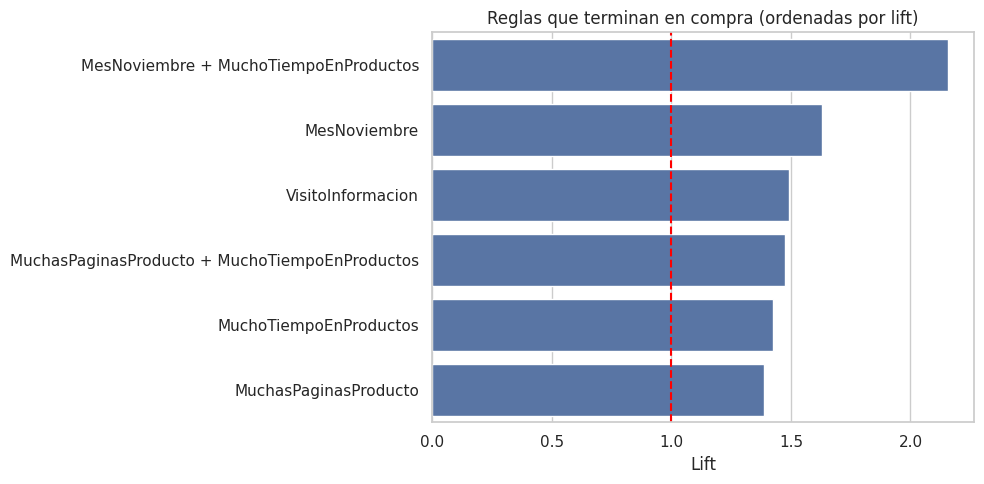

In [25]:
top = reglas.head(8).copy()
etiquetas = top['antecedents'].apply(lambda s: ' + '.join(sorted(s)))

plt.figure(figsize=(10, 5))
sns.barplot(x=top['lift'].values, y=etiquetas.values, color='#4C72B0')
plt.axvline(1, color='red', ls='--')
plt.xlabel('Lift')
plt.title('Reglas que terminan en compra (ordenadas por lift)')
plt.tight_layout()
plt.show()

**Observaciones:**

- Se obtuvieron **6 reglas** cuyo consecuente es exactamente `Compra`.
- La más fuerte es `MesNoviembre + MuchoTiempoEnProductos -> Compra`, con soporte **0.0506**, confianza **33.73 %** y lift **2.16**: esas sesiones compran más del doble que el promedio.
- `MesNoviembre -> Compra` tiene confianza 25.49 % y lift 1.63; `VisitoInformacion -> Compra`, confianza 23.30 % y lift 1.49.
- Todas las reglas tienen lift > 1, por encima de la línea roja de referencia.
- Son asociaciones descriptivas: noviembre no causa la compra, solo se asocia en este dataset.

## Cierre

- La **regresión lineal** explica parte de la variación de la duración (R² = 0.69 en prueba), pero falla en sesiones largas. Como mejora futura se probarían transformaciones de la variable objetivo.
- **Apriori** encontró 6 reglas; la combinación de noviembre con mucho tiempo en productos es la más interesante (lift 2.16).
- A diferencia de la clasificación (que predice `Revenue`), Apriori describe condiciones asociadas a la compra; K-Means agrupa sesiones sin usar `Revenue`.
- Limitaciones: exclusión de `PageValues`, asimetría de la duración, umbrales de Apriori elegidos empíricamente y correlación entre indicadores.

Estas observaciones se usarán en el informe final del equipo.